# Ciprofloxacin Resistance Prediction — k-mer + Random Forest

In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

RANDOM_STATE = 42
K = 5

print("Imports successful.")
print("Working directory:", Path.cwd())


Imports successful.
Working directory: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\notebooks


In [3]:

from pathlib import Path
import pandas as pd

# Locate the project root
ROOT = Path.cwd()

if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

PROCESSED_DIR = ROOT / "data" / "processed"

labels_path = PROCESSED_DIR / "ciprofloxacin_genome_level.csv"
manifest_path = PROCESSED_DIR / "genome_retrieval_manifest.csv"

# Load the existing files
labels = pd.read_csv(labels_path)
manifest = pd.read_csv(manifest_path)

print("Project root:", ROOT)
print("\nLABEL DATA")
print("Shape:", labels.shape)
print("Columns:", labels.columns.tolist())
display(labels.head(5))

print("\nRETRIEVAL MANIFEST")
print("Shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())
display(manifest.head(5))


Project root: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN

LABEL DATA
Shape: (1205, 3)
Columns: ['Genome ID', 'Phenotype', 'Label']


,Genome ID,Phenotype,Label
0,1280.15865,"('Susceptible',)",0
1,1280.15866,"('Susceptible',)",0
2,1280.15867,"('Susceptible',)",0
3,1280.15868,"('Susceptible',)",0
4,1280.15869,"('Susceptible',)",0



RETRIEVAL MANIFEST
Shape: (1205, 5)
Columns: ['Genome ID', 'Phenotype', 'Label', 'Metadata Available', 'FASTA Available']


,Genome ID,Phenotype,Label,Metadata Available,FASTA Available
0,1280.15865,"('Susceptible',)",0,True,True
1,1280.15866,"('Susceptible',)",0,True,True
2,1280.15867,"('Susceptible',)",0,True,True
3,1280.15868,"('Susceptible',)",0,True,True
4,1280.15869,"('Susceptible',)",0,True,True


In [4]:

# Check genome IDs and labels before feature extraction

GENOME_DIR = ROOT / "data" / "genomes"

print("Genome directory exists:", GENOME_DIR.exists())

# 1. Check duplicate IDs
print("\nDuplicate genome IDs")
print("Labels:", labels["Genome ID"].duplicated().sum())
print("Manifest:", manifest["Genome ID"].duplicated().sum())

# 2. Check binary label distribution
print("\nLabel counts:")
print(labels["Label"].value_counts(dropna=False).sort_index())

print("\nPhenotype counts:")
print(labels["Phenotype"].value_counts(dropna=False))

# 3. Check agreement between labels and manifest
check = labels.merge(
    manifest[["Genome ID", "Label", "FASTA Available"]],
    on="Genome ID",
    how="outer",
    suffixes=("_label", "_manifest"),
    indicator=True,
    validate="one_to_one"
)

print("\nID matching:")
print(check["_merge"].value_counts())

matched = check["_merge"].eq("both")
print(
    "Label disagreements:",
    (
        check.loc[matched, "Label_label"]
        != check.loc[matched, "Label_manifest"]
    ).sum()
)

print("\nFASTA availability recorded in manifest:")
print(check["FASTA Available"].value_counts(dropna=False))

# 4. Inspect actual files
if GENOME_DIR.exists():
    fasta_files = [
        p for p in GENOME_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".fna", ".fasta", ".fa", ".fas"}
    ]

    print("\nActual FASTA files found:", len(fasta_files))
    print("Example filenames:")
    for path in fasta_files[:10]:
        print(path.name)
else:
    print("Please check the genome directory path.")


Genome directory exists: True

Duplicate genome IDs
Labels: 0
Manifest: 0

Label counts:
Label
0    691
1    514
Name: count, dtype: int64

Phenotype counts:
Phenotype
('Susceptible',)    691
('Resistant',)      514
Name: count, dtype: int64

ID matching:
_merge
both          1205
left_only        0
right_only       0
Name: count, dtype: int64
Label disagreements: 0

FASTA availability recorded in manifest:
FASTA Available
True     1138
False      67
Name: count, dtype: int64

Actual FASTA files found: 1138
Example filenames:
1280.15865.fna
1280.15866.fna
1280.15867.fna
1280.15868.fna
1280.15869.fna
1280.15871.fna
1280.15872.fna
1280.15873.fna
1280.15874.fna
1280.15875.fna


In [5]:

# Map each FASTA file to its genome ID using its filename
fasta_by_id = {
    path.stem: path
    for path in GENOME_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".fna", ".fasta", ".fa", ".fas"}
}

# Normalize IDs to strings for reliable matching
labels["Genome ID"] = labels["Genome ID"].astype(str)
manifest["Genome ID"] = manifest["Genome ID"].astype(str)

# Keep only labeled genomes whose exact ID has a FASTA file
cohort = labels[
    labels["Genome ID"].isin(fasta_by_id)
].copy()

cohort["FASTA Path"] = cohort["Genome ID"].map(fasta_by_id)

# Report cohort statistics
print("Eligible genomes:", len(cohort))
print("\nClass counts:")
print(cohort["Label"].value_counts().sort_index())

print("\nGenome ID examples:")
display(cohort[["Genome ID", "Phenotype", "Label", "FASTA Path"]].head(10))

# Check that every selected genome has a matching file
assert cohort["Genome ID"].is_unique
assert cohort["FASTA Path"].notna().all()
assert set(cohort["Label"].unique()).issubset({0, 1})

print("\nAll selected IDs have matching FASTA paths.")


Eligible genomes: 1138

Class counts:
Label
0    664
1    474
Name: count, dtype: int64

Genome ID examples:


,Genome ID,Phenotype,Label,FASTA Path
0,1280.15865,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
1,1280.15866,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
2,1280.15867,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
3,1280.15868,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
4,1280.15869,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
6,1280.15871,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
7,1280.15872,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
8,1280.15873,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
9,1280.15874,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...
10,1280.15875,"('Susceptible',)",0,d:\4th Year 7th Sem\AI and Systems Biology in ...



All selected IDs have matching FASTA paths.


In [6]:

# Split genome IDs before feature extraction

train_df, temp_df = train_test_split(
    cohort,
    test_size=0.30,
    stratify=cohort["Label"],
    random_state=RANDOM_STATE
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Label"],
    random_state=RANDOM_STATE
)

# Reset row indices for convenience
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Verify no genome appears in multiple splits
train_ids = set(train_df["Genome ID"])
val_ids = set(val_df["Genome ID"])
test_ids = set(test_df["Genome ID"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Training genomes:", len(train_df))
print("Validation genomes:", len(val_df))
print("Test genomes:", len(test_df))

print("\nClass counts by split:")
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(df["Label"].value_counts().sort_index())

print("\nNo genome IDs overlap between splits.")


Training genomes: 796
Validation genomes: 171
Test genomes: 171

Class counts by split:

Train:
Label
0    464
1    332
Name: count, dtype: int64

Validation:
Label
0    100
1     71
Name: count, dtype: int64

Test:
Label
0    100
1     71
Name: count, dtype: int64

No genome IDs overlap between splits.


In [7]:

from collections import Counter
from itertools import product
import numpy as np

# All possible DNA 5-mers in a fixed, consistent order
KMER_LIST = [
    "".join(chars)
    for chars in product("ACGT", repeat=K)
]
KMER_INDEX = {kmer: i for i, kmer in enumerate(KMER_LIST)}

def extract_kmer_frequencies(fasta_path, k=K):
    """Return normalized k-mer frequencies for one genome FASTA."""
    counts = np.zeros(4**k, dtype=np.float64)
    valid_total = 0

    # Read contigs one at a time; never join across contig boundaries
    with open(fasta_path, "r", encoding="utf-8") as handle:
        for line in handle:
            if line.startswith(">"):
                continue

            sequence = line.strip().upper()
            if len(sequence) < k:
                continue

            for i in range(len(sequence) - k + 1):
                kmer = sequence[i:i + k]

                # Skip ambiguous or non-DNA windows
                if all(base in "ACGT" for base in kmer):
                    counts[KMER_INDEX[kmer]] += 1
                    valid_total += 1

    if valid_total == 0:
        raise ValueError(
            f"No valid {k}-mers found in {fasta_path}"
        )

    return counts / valid_total

# Test on one training genome first
example_path = train_df.loc[0, "FASTA Path"]
example_features = extract_kmer_frequencies(example_path)

print("Example genome:", train_df.loc[0, "Genome ID"])
print("Feature vector shape:", example_features.shape)
print("Sum of frequencies:", example_features.sum())
print("Non-zero features:", np.count_nonzero(example_features))

assert example_features.shape == (1024,)
assert np.isclose(example_features.sum(), 1.0)
print("\nSingle-genome feature extraction passed.")


Example genome: 1280.59769
Feature vector shape: (1024,)
Sum of frequencies: 1.0
Non-zero features: 1024

Single-genome feature extraction passed.


In [8]:

import time

FEATURE_DIR = ROOT / "data" / "processed" / "kmer_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

def build_feature_matrix(df, split_name):
    start = time.time()
    rows = []

    for i, (_, row) in enumerate(df.iterrows(), start=1):
        features = extract_kmer_frequencies(row["FASTA Path"])
        rows.append(features)

        if i % 25 == 0 or i == len(df):
            elapsed = time.time() - start
            print(
                f"{split_name}: {i}/{len(df)} genomes processed "
                f"({elapsed / 60:.1f} min elapsed)"
            )

    X = np.vstack(rows)

    # Save features with genome IDs for traceability
    feature_df = pd.DataFrame(X, columns=KMER_LIST)
    feature_df.insert(0, "Genome ID", df["Genome ID"].to_numpy())
    feature_df.to_csv(
        FEATURE_DIR / f"{split_name}_5mer_features.csv",
        index=False
    )

    return X

X_train = build_feature_matrix(train_df, "train")
X_val = build_feature_matrix(val_df, "validation")
X_test = build_feature_matrix(test_df, "test")

y_train = train_df["Label"].to_numpy()
y_val = val_df["Label"].to_numpy()
y_test = test_df["Label"].to_numpy()

print("\nFeature extraction complete.")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("Saved to:", FEATURE_DIR)


train: 25/796 genomes processed (1.7 min elapsed)
train: 50/796 genomes processed (3.6 min elapsed)
train: 75/796 genomes processed (5.6 min elapsed)
train: 100/796 genomes processed (7.8 min elapsed)
train: 125/796 genomes processed (10.0 min elapsed)
train: 150/796 genomes processed (12.1 min elapsed)
train: 175/796 genomes processed (14.2 min elapsed)
train: 200/796 genomes processed (16.3 min elapsed)
train: 225/796 genomes processed (18.4 min elapsed)
train: 250/796 genomes processed (20.6 min elapsed)
train: 275/796 genomes processed (22.8 min elapsed)
train: 300/796 genomes processed (24.9 min elapsed)
train: 325/796 genomes processed (26.5 min elapsed)
train: 350/796 genomes processed (28.4 min elapsed)
train: 375/796 genomes processed (30.6 min elapsed)
train: 400/796 genomes processed (32.7 min elapsed)
train: 425/796 genomes processed (34.9 min elapsed)
train: 450/796 genomes processed (37.0 min elapsed)
train: 475/796 genomes processed (37.8 min elapsed)
train: 500/796 geno

In [8]:

from itertools import product
import numpy as np
import time

K = 5

# Fixed feature order: all 1,024 possible A/C/G/T 5-mers
KMER_LIST = [
    "".join(chars)
    for chars in product("ACGT", repeat=K)
]

# Encode A, C, G, T as 0, 1, 2, 3.
# All other bytes are treated as invalid bases.
BASE_LOOKUP = np.full(256, 255, dtype=np.uint8)
for base, code in zip(b"ACGT", range(4)):
    BASE_LOOKUP[base] = code

KMER_POWERS = (
    4 ** np.arange(K - 1, -1, -1)
).astype(np.int32)


def extract_kmer_frequencies(fasta_path, k=K):
    """
    Calculate normalized k-mer frequencies for one genome FASTA.

    Handles wrapped sequence lines and multiple contigs.
    Never counts a k-mer across contig boundaries.
    Skips windows containing ambiguous/non-ACGT bases.
    """
    if k != K:
        raise ValueError(
            "This extractor is configured for K=5. "
            "Update the feature encoding before changing K."
        )

    counts = np.zeros(4**k, dtype=np.int64)
    valid_total = 0
    contig_parts = []

    def count_contig(parts):
        if not parts:
            return 0

        sequence = b"".join(parts).upper()

        if len(sequence) < k:
            return 0

        codes = BASE_LOOKUP[
            np.frombuffer(sequence, dtype=np.uint8)
        ]

        n_windows = len(codes) - k + 1

        encoded = np.zeros(n_windows, dtype=np.int32)
        valid = np.ones(n_windows, dtype=bool)

        for offset in range(k):
            bases = codes[offset:offset + n_windows]
            valid &= bases < 4
            encoded += bases.astype(np.int32) * KMER_POWERS[offset]

        encoded_valid = encoded[valid]

        counts[:] += np.bincount(
            encoded_valid,
            minlength=4**k
        )

        return len(encoded_valid)

    with open(fasta_path, "rb") as handle:
        for line in handle:
            if line.startswith(b">"):
                valid_total += count_contig(contig_parts)
                contig_parts = []
            else:
                line = line.strip()
                if line:
                    contig_parts.append(line)

    # Process the final contig
    valid_total += count_contig(contig_parts)

    if valid_total == 0:
        raise ValueError(
            f"No valid {k}-mers found in {fasta_path}"
        )

    frequencies = counts.astype(np.float64) / valid_total

    return frequencies


# Verify on one training genome
example_path = train_df.loc[0, "FASTA Path"]
example_features = extract_kmer_frequencies(example_path)

print("Feature vector shape:", example_features.shape)
print("Frequency sum:", example_features.sum())
print("Non-zero features:", np.count_nonzero(example_features))

assert example_features.shape == (1024,)
assert np.isclose(example_features.sum(), 1.0)

print("Corrected extractor passed.")


Feature vector shape: (1024,)
Frequency sum: 1.0
Non-zero features: 1024
Corrected extractor passed.


In [10]:

FEATURE_DIR = ROOT / "data" / "processed" / "kmer_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)


def build_feature_matrix(df, split_name):
    start_time = time.time()
    rows = []

    for i, (_, row) in enumerate(df.iterrows(), start=1):
        features = extract_kmer_frequencies(row["FASTA Path"])
        rows.append(features)

        if i % 50 == 0 or i == len(df):
            elapsed = (time.time() - start_time) / 60
            print(
                f"{split_name}: {i}/{len(df)} genomes "
                f"processed | {elapsed:.1f} min elapsed"
            )

    X = np.vstack(rows)

    feature_df = pd.DataFrame(X, columns=KMER_LIST)
    feature_df.insert(
        0, "Genome ID", df["Genome ID"].astype(str).to_numpy()
    )

    output_path = FEATURE_DIR / f"{split_name}_5mer_features.csv"
    feature_df.to_csv(output_path, index=False)

    print(f"Saved: {output_path}")
    return X


# Extract corrected features for each split
X_train = build_feature_matrix(train_df, "train")
X_val = build_feature_matrix(val_df, "validation")
X_test = build_feature_matrix(test_df, "test")

# Labels remain aligned to their corresponding genome rows
y_train = train_df["Label"].to_numpy(dtype=int)
y_val = val_df["Label"].to_numpy(dtype=int)
y_test = test_df["Label"].to_numpy(dtype=int)

print("\nCorrected feature extraction complete.")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("Output directory:", FEATURE_DIR)

assert X_train.shape == (len(train_df), 1024)
assert X_val.shape == (len(val_df), 1024)
assert X_test.shape == (len(test_df), 1024)


train: 50/796 genomes processed | 0.0 min elapsed
train: 100/796 genomes processed | 0.1 min elapsed
train: 150/796 genomes processed | 0.1 min elapsed
train: 200/796 genomes processed | 0.2 min elapsed
train: 250/796 genomes processed | 0.3 min elapsed
train: 300/796 genomes processed | 0.3 min elapsed
train: 350/796 genomes processed | 0.4 min elapsed
train: 400/796 genomes processed | 0.4 min elapsed
train: 450/796 genomes processed | 0.5 min elapsed
train: 500/796 genomes processed | 0.5 min elapsed
train: 550/796 genomes processed | 0.6 min elapsed
train: 600/796 genomes processed | 0.6 min elapsed
train: 650/796 genomes processed | 0.7 min elapsed
train: 700/796 genomes processed | 0.7 min elapsed
train: 750/796 genomes processed | 0.8 min elapsed
train: 796/796 genomes processed | 0.8 min elapsed
Saved: d:\4th Year 7th Sem\AI and Systems Biology in Precision Medicine\AMR_Genome_CNN\data\processed\kmer_features\train_5mer_features.csv
validation: 50/171 genomes processed | 0.1 mi

In [11]:

for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    saved = pd.read_csv(
        FEATURE_DIR / f"{split_name}_5mer_features.csv"
    )

    assert len(saved) == len(df)
    assert saved["Genome ID"].astype(str).tolist() == (
        df["Genome ID"].astype(str).tolist()
    )

    X_saved = saved[KMER_LIST].to_numpy()

    assert X_saved.shape == (len(df), 1024)
    assert np.isfinite(X_saved).all()
    assert (X_saved >= 0).all()
    assert np.allclose(X_saved.sum(axis=1), 1.0)

    print(
        f"{split_name}: {len(saved)} genomes, "
        f"{X_saved.shape[1]} features — all checks passed"
    )

print("\nAll feature matrices verified.")


train: 796 genomes, 1024 features — all checks passed
validation: 171 genomes, 1024 features — all checks passed
test: 171 genomes, 1024 features — all checks passed

All feature matrices verified.


## Training Random Forest

In [12]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import numpy as np
import time

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start = time.time()
rf_model.fit(X_train, y_train)

print(f"Training completed in {time.time() - start:.1f} seconds.")
print("Trees:", rf_model.n_estimators)
print("Training genomes:", len(y_train))


Training completed in 1.3 seconds.
Trees: 300
Training genomes: 796


In [13]:

y_val_pred = rf_model.predict(X_val)
y_val_prob = rf_model.predict_proba(X_val)[:, 1]

print("VALIDATION RESULTS")
print("=" * 45)

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_val, y_val_pred), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, y_val_prob), 4)
)

print(
    "PR-AUC (average precision):",
    round(average_precision_score(y_val, y_val_prob), 4)
)

print("\nClassification report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=["Susceptible", "Resistant"],
        digits=4,
        zero_division=0
    )
)

print("Confusion matrix (rows = actual, columns = predicted):")
print(
    confusion_matrix(y_val, y_val_pred, labels=[0, 1])
)


VALIDATION RESULTS
Balanced accuracy: 0.7608
ROC-AUC: 0.8879
PR-AUC (average precision): 0.8682

Classification report:
              precision    recall  f1-score   support

 Susceptible     0.7623    0.9300    0.8378       100
   Resistant     0.8571    0.5915    0.7000        71

    accuracy                         0.7895       171
   macro avg     0.8097    0.7608    0.7689       171
weighted avg     0.8017    0.7895    0.7806       171

Confusion matrix (rows = actual, columns = predicted):
[[93  7]
 [29 42]]


## Training Logistic Regression

In [14]:
from sklearn.linear_model import LogisticRegression
import time

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    C=1.0,
    random_state=RANDOM_STATE
)

start = time.time()
lr_model.fit(X_train, y_train)

print(f"Logistic Regression trained in {time.time() - start:.2f} seconds.")

Logistic Regression trained in 0.02 seconds.


In [15]:
# Evaluate Logistic Regression on the validation set
y_val_pred_lr = lr_model.predict(X_val)
y_val_prob_lr = lr_model.predict_proba(X_val)[:, 1]

print("LOGISTIC REGRESSION — VALIDATION RESULTS")
print("=" * 48)

print(f"Balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred_lr):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_val, y_val_prob_lr):.4f}")
print(f"PR-AUC:            {average_precision_score(y_val, y_val_prob_lr):.4f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_pred_lr,
    labels=[0, 1],
    target_names=["Susceptible", "Resistant"],
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_val, y_val_pred_lr, labels=[0, 1]))

LOGISTIC REGRESSION — VALIDATION RESULTS
Balanced accuracy: 0.5000
ROC-AUC:           0.5000
PR-AUC:            0.4152

Classification report:
              precision    recall  f1-score   support

 Susceptible       0.58      1.00      0.74       100
   Resistant       0.00      0.00      0.00        71

    accuracy                           0.58       171
   macro avg       0.29      0.50      0.37       171
weighted avg       0.34      0.58      0.43       171

Confusion matrix (rows = actual, columns = predicted):
[[100   0]
 [ 71   0]]


## inspect Random Forest feature importance

In [16]:
# Inspect the most important 5-mer features
import pandas as pd

feature_importance = pd.DataFrame({
    "5-mer": KMER_LIST,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("TOP 20 MOST IMPORTANT 5-MERS")
display(feature_importance.head(20).reset_index(drop=True))

TOP 20 MOST IMPORTANT 5-MERS


,5-mer,Importance
0,CGGAC,0.012684
1,GGACC,0.011578
2,GGCGC,0.011133
3,ACGCG,0.010757
4,GGCAC,0.010010
5,GAACT,0.009438
6,GGGCC,0.009357
7,GAATC,0.008546
8,TATAT,0.007680
9,ACATT,0.007599


In [17]:
# Compare both models on the validation set

comparison = pd.DataFrame([
    {
        "Model": "5-mer + Random Forest",
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, rf_model.predict(X_val)
        ),
        "ROC-AUC": roc_auc_score(
            y_val, rf_model.predict_proba(X_val)[:, 1]
        ),
        "PR-AUC": average_precision_score(
            y_val, rf_model.predict_proba(X_val)[:, 1]
        ),
    },
    {
        "Model": "5-mer + Logistic Regression",
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, lr_model.predict(X_val)
        ),
        "ROC-AUC": roc_auc_score(
            y_val, lr_model.predict_proba(X_val)[:, 1]
        ),
        "PR-AUC": average_precision_score(
            y_val, lr_model.predict_proba(X_val)[:, 1]
        ),
    }
])

display(comparison.round(4))

,Model,Balanced Accuracy,ROC-AUC,PR-AUC
0,5-mer + Random Forest,0.7608,0.8879,0.8682
1,5-mer + Logistic Regression,0.5000,0.5000,0.4152


In [18]:
# Final evaluation of the selected Random Forest model
y_test_pred = rf_model.predict(X_test)
y_test_prob = rf_model.predict_proba(X_test)[:, 1]

print("RANDOM FOREST — FINAL TEST RESULTS")
print("=" * 48)

print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_test_prob):.4f}")
print(f"PR-AUC:            {average_precision_score(y_test, y_test_prob):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Susceptible", "Resistant"],
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

RANDOM FOREST — FINAL TEST RESULTS
Balanced accuracy: 0.7808
ROC-AUC:           0.9097
PR-AUC:            0.9061

Classification report:
              precision    recall  f1-score   support

 Susceptible       0.77      0.97      0.86       100
   Resistant       0.93      0.59      0.72        71

    accuracy                           0.81       171
   macro avg       0.85      0.78      0.79       171
weighted avg       0.84      0.81      0.80       171

Confusion matrix (rows = actual, columns = predicted):
[[97  3]
 [29 42]]


## investigate the classification threshold

In [19]:
from sklearn.metrics import precision_score, recall_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:

    predictions = (rf_model.predict_proba(X_val)[:, 1] >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Resistant Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Resistant Recall": recall_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Balanced Accuracy,Resistant Precision,Resistant Recall
0,0.30,0.7368,0.5877,0.9437
1,0.35,0.7816,0.6667,0.8732
2,0.40,0.7985,0.7250,0.8169
3,0.45,0.7971,0.8197,0.7042
4,0.50,0.7608,0.8571,0.5915


## evaluate the selected threshold on the test set

In [20]:
# Apply validation-selected threshold to the test set

SELECTED_THRESHOLD = 0.40

y_test_pred_040 = (
    rf_model.predict_proba(X_test)[:, 1] >= SELECTED_THRESHOLD
).astype(int)

print("RANDOM FOREST — TEST RESULTS AT THRESHOLD 0.40")
print("=" * 55)

print(f"Threshold: {SELECTED_THRESHOLD}")

print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_test_pred_040):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred_040,
    labels=[0, 1],
    target_names=["Susceptible", "Resistant"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_test_pred_040, labels=[0, 1]))

RANDOM FOREST — TEST RESULTS AT THRESHOLD 0.40
Threshold: 0.4
Balanced accuracy: 0.8414

Classification report:
              precision    recall  f1-score   support

 Susceptible       0.86      0.88      0.87       100
   Resistant       0.83      0.80      0.81        71

    accuracy                           0.85       171
   macro avg       0.84      0.84      0.84       171
weighted avg       0.85      0.85      0.85       171

Confusion matrix:
[[88 12]
 [14 57]]


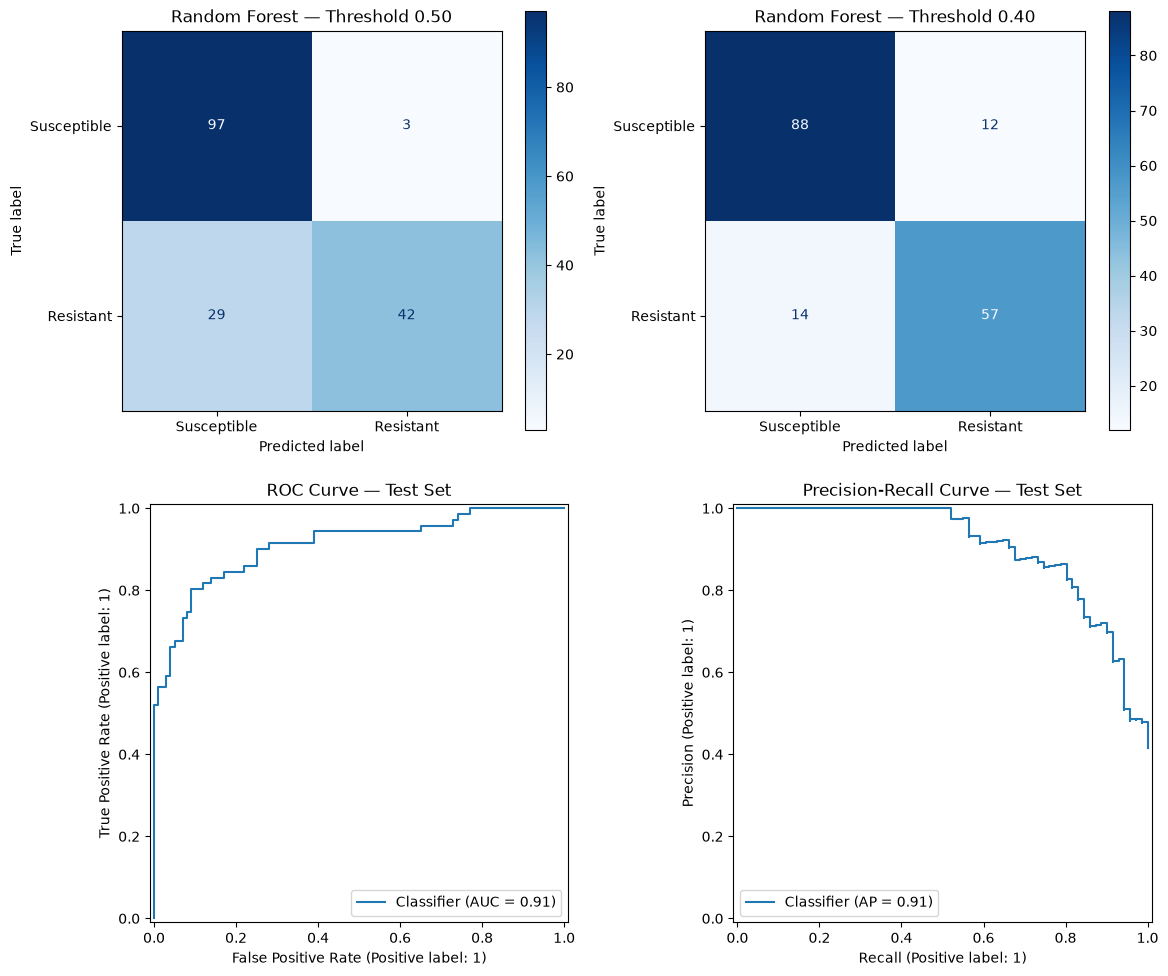

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Confusion matrix at threshold 0.50
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Susceptible", "Resistant"],
    cmap="Blues",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Random Forest — Threshold 0.50")

# Confusion matrix at threshold 0.40
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_040,
    display_labels=["Susceptible", "Resistant"],
    cmap="Blues",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Random Forest — Threshold 0.40")

# ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob,
    ax=axes[1, 0]
)
axes[1, 0].set_title("ROC Curve — Test Set")

# Precision-recall curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Precision-Recall Curve — Test Set")

plt.tight_layout()
plt.show()